In [ ]:
!pip install gym_bandits

In [ ]:
import gym
import gym_bandits
import numpy as np

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
env = gym.make("MultiarmedBandits-v0")

In [ ]:
print(env.observation_space)

Discrete(1)


In [ ]:
print(env.action_space)

Discrete(10)


In [ ]:
n_arms = env.action_space.n
num_epsiodes = 500
epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)
all_reward = []
action_history = []
warnings.filterwarnings("ignore",category = DeprecationWarning)

In [ ]:
for episode in range(num_epsiodes):
  env.reset()
  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_values)
    observation, reward , done , info = env.step(action)
  counts[action] += 1
  reward_sums[action] += reward
  q_values[action] = reward_sums[action] / counts[action]
  all_reward.append(reward)
  action_history.append(action)
env.close()

Estimated Q-Values for each arm: [-0.1  -0.22 -0.1  -0.   -0.3  -1.69 -0.65 -0.71 -0.58 -0.86]
Number of times each arm was selected: [  7   8  93 362   5   4   7   5   3   7]
Average reward overall episode -0.071


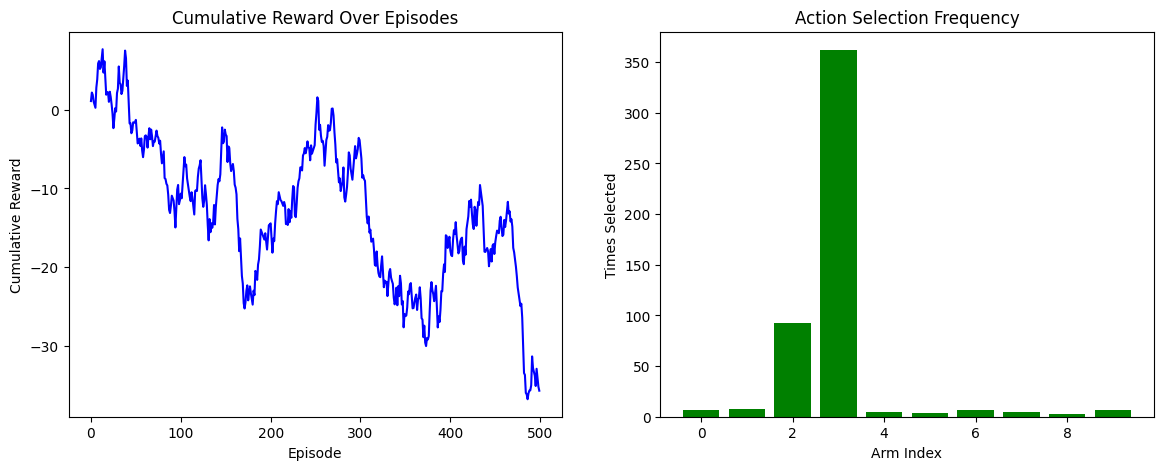

In [ ]:
import matplotlib.pyplot as plt
print("Estimated Q-Values for each arm:",np.round(q_values,2))
print("Number of times each arm was selected:",counts.astype(int))
print("Average reward overall episode",round(np.mean(all_reward),3))

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(np.cumsum(all_reward),color = 'blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel('Episode')
plt.ylabel('Cumulative Reward')

plt.subplot(1,2,2)
plt.bar(np.arange(n_arms),counts,color = 'green')
plt.title("Action Selection Frequency")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")
plt.show()